In [5]:
import pandas as pd

fred = pd.read_csv("Data/raw/fred_daily.csv")
yahoo = pd.read_csv("Data/raw/yahoo_daily.csv")

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

In [2]:
%pip install arch

   ---------------------------------------- 0.0/934.4 kB ? eta -:--:--
   ---------------------------------------- 934.4/934.4 kB 24.3 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
from arch import arch_model

In [6]:
yahoo=pd.read_csv("Data/raw/yahoo_daily.csv",index_col="date",parse_dates=True)
yahoo.head()

,wti_fut,brent_fut,gasoline,heating_oil,natgas,xle,sp500,vix,dxy,gold,copper
date,,,,,,,,,,,
1980-01-02,NaN,NaN,NaN,NaN,NaN,NaN,105.760002,NaN,85.320000,NaN,NaN
1980-01-03,NaN,NaN,NaN,NaN,NaN,NaN,105.220001,NaN,85.260002,NaN,NaN
1980-01-04,NaN,NaN,NaN,NaN,NaN,NaN,106.519997,NaN,85.230003,NaN,NaN
1980-01-07,NaN,NaN,NaN,NaN,NaN,NaN,106.809998,NaN,84.790001,NaN,NaN
1980-01-08,NaN,NaN,NaN,NaN,NaN,NaN,108.949997,NaN,85.070000,NaN,NaN


In [7]:
price=yahoo["wti_fut"].copy()
price=price.dropna()
print(price.head())
print(price.tail())
print("Number of observations:",len(price))

date
2000-08-23    32.049999
2000-08-24    31.629999
2000-08-25    32.049999
2000-08-28    32.869999
2000-08-29    32.720001
Name: wti_fut, dtype: float64
date
2026-10-02    91.110001
2026-10-05    89.430000
2026-10-06    89.440002
2026-10-07    88.279999
2026-10-08    90.820000
Name: wti_fut, dtype: float64
Number of observations: 6560


In [10]:
price_positive=price.copy()
price_positive[price_positive<=0]=np.nan
ret=np.log(price_positive).diff().dropna()
ret.head()

date
2000-08-24   -0.013191
2000-08-25    0.013191
2000-08-28    0.025263
2000-08-29   -0.004574
2000-08-30    0.020569
Name: wti_fut, dtype: float64

In [11]:
print("Return of observations:",len(ret))
print("Mean:",ret.mean())
print("Std:", ret.std())

Return of observations: 6557
Mean: 0.0002506112768034945
Std: 0.026289679316585546


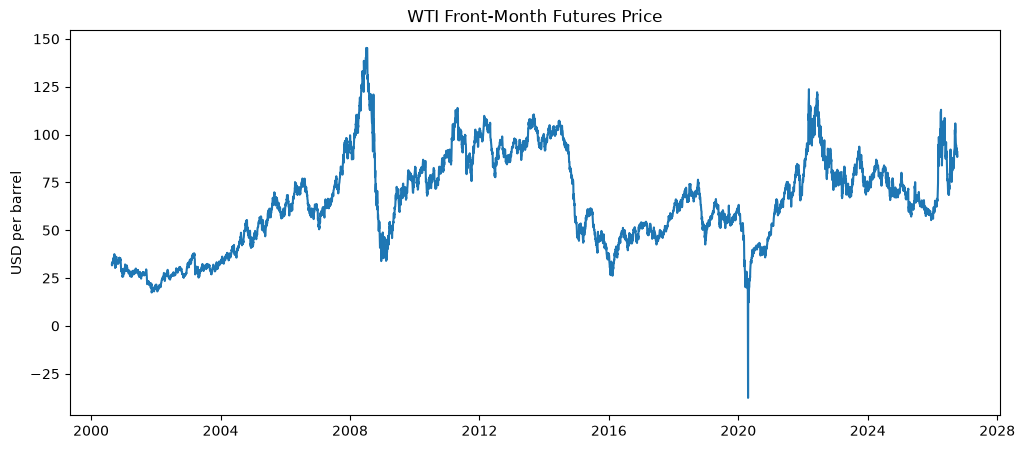

In [12]:
plt.figure(figsize=(12,5))
plt.plot(price)
plt.title("WTI Front-Month Futures Price")
plt.ylabel("USD per barrel")
plt.show()

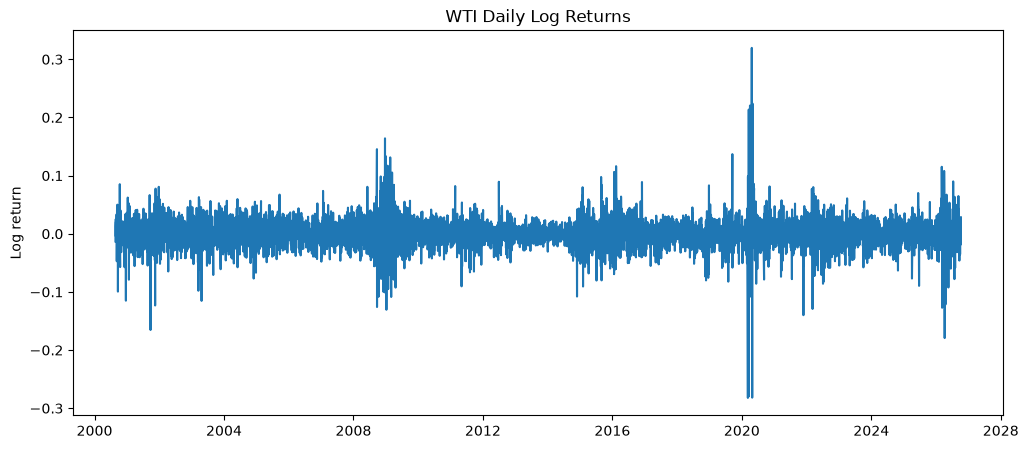

In [13]:
plt.figure(figsize=(12,5))
plt.plot(ret)
plt.title("WTI Daily Log Returns")
plt.ylabel("Log return")
plt.show()

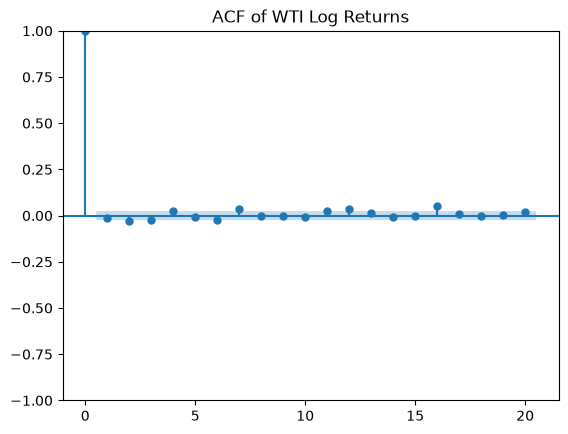

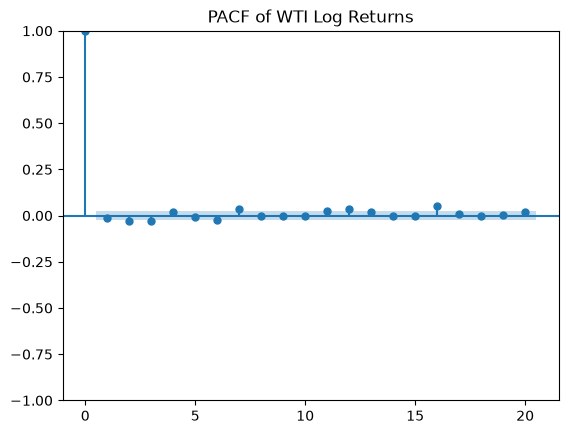

In [15]:
plot_acf(ret,lags=20)
plt.title("ACF of WTI Log Returns")
plt.show()
plot_pacf(ret,lags=20)
plt.title("PACF of WTI Log Returns")
plt.show()

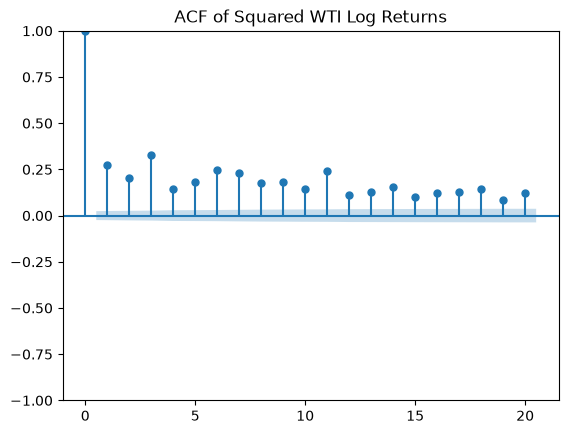

In [16]:
plot_acf(ret**2,lags=20)
plt.title("ACF of Squared WTI Log Returns")
plt.show()

In [17]:
split = int(len(ret) * 0.8)

train = ret.iloc[:split]
test = ret.iloc[split:]

print("Training period:")
print(train.index[0], "to", train.index[-1])

print("\nTest period:")
print(test.index[0], "to", test.index[-1])

print("\nTrain size:", len(train))
print("Test size:", len(test))

Training period:
2000-08-24 00:00:00 to 2021-07-21 00:00:00

Test period:
2021-07-22 00:00:00 to 2026-10-08 00:00:00

Train size: 5245
Test size: 1312


In [18]:
results = []

for p in range(4):
    for q in range(4):
        try:
            model = ARIMA(
                train,
                order=(p,0,q),
                trend="c"
            ).fit()

            results.append({
                "p": p,
                "q": q,
                "AIC": model.aic,
                "BIC": model.bic
            })

        except:
            pass

arma_table = pd.DataFrame(results).sort_values("AIC")

arma_table

C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init

,p,q,AIC,BIC
12,3,0,-23253.818758,-23220.993606
2,0,2,-23253.793713,-23227.533591
3,0,3,-23253.680066,-23220.854913
8,2,0,-23253.632794,-23227.372672
1,0,1,-23253.121330,-23233.426239
4,1,0,-23252.978093,-23233.283002
11,2,3,-23252.261203,-23206.305989
6,1,2,-23252.090072,-23219.264919
0,0,0,-23251.956346,-23238.826285
13,3,1,-23251.784463,-23212.394280


In [19]:
ar3=ARIMA(train,order=(3,0,0),trend="c").fit()
print(ar3.summary())

C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                wti_fut   No. Observations:                 5245
Model:                 ARIMA(3, 0, 0)   Log Likelihood               11631.909
Date:                Sat, 10 Oct 2026   AIC                         -23253.819
Time:                        21:24:17   BIC                         -23220.994
Sample:                             0   HQIC                        -23242.342
                               - 5245                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003      0.000      0.768      0.443      -0.000       0.001
ar.L1         -0.0250      0.005     -4.664      0.000      -0.036      -0.015
ar.L2         -0.0229      0.007     -3.485      0.0

In [20]:
ma2=ARIMA(train,order=(0,0,2),trend="c").fit()
print(ma2.summary())

C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                wti_fut   No. Observations:                 5245
Model:                 ARIMA(0, 0, 2)   Log Likelihood               11630.897
Date:                Sat, 10 Oct 2026   AIC                         -23253.794
Time:                        21:24:24   BIC                         -23227.534
Sample:                             0   HQIC                        -23244.612
                               - 5245                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0003      0.000      0.751      0.453      -0.000       0.001
ma.L1         -0.0246      0.005     -4.605      0.000      -0.035      -0.014
ma.L2         -0.0222      0.006     -3.601      0.0

In [21]:
acorr_ljungbox(ar3.resid, lags=[10], return_df=True)

,lb_stat,lb_pvalue
10,12.973652,0.225149


In [22]:
acorr_ljungbox(ma2.resid, lags=[10], return_df=True)

,lb_stat,lb_pvalue
10,14.477798,0.152292


In [23]:
ma2_refined=ARIMA(train,order=(0,0,2),trend="n").fit()
print(ma2_refined.summary())

C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                wti_fut   No. Observations:                 5245
Model:                 ARIMA(0, 0, 2)   Log Likelihood               11630.606
Date:                Sat, 10 Oct 2026   AIC                         -23255.213
Time:                        22:11:26   BIC                         -23235.518
Sample:                             0   HQIC                        -23248.327
                               - 5245                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.0245      0.005     -4.597      0.000      -0.035      -0.014
ma.L2         -0.0221      0.006     -3.591      0.000      -0.034      -0.010
sigma2         0.0007    4.4e-06    157.797      0.0

In [24]:
acorr_ljungbox(
    ma2_refined.resid,
    lags=[10],
    model_df=2,
    return_df=True)

,lb_stat,lb_pvalue
10,14.478362,0.070118


In [25]:
resid = ma2_refined.resid
resid_sq = resid ** 2

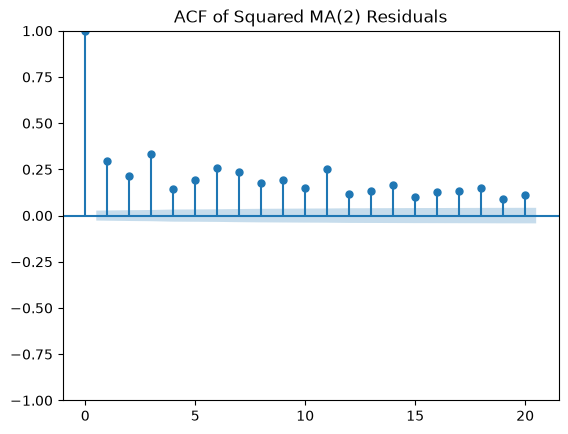

In [26]:
plot_acf(resid_sq,lags=20)
plt.title("ACF of Squared MA(2) Residuals")
plt.show()

In [30]:
arch_1b=acorr_ljungbox(resid_sq,lags=[10],return_df=True)
arch_1b

,lb_stat,lb_pvalue
10,2700.518816,0.0


In [31]:
garch_norm = arch_model(resid* 100,mean="Zero",vol="GARCH",p=1,q=1,dist="normal").fit(disp="off")
print(garch_norm.summary())

                       Zero Mean - GARCH Model Results                        
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -11510.0
Distribution:                  Normal   AIC:                           23026.1
Method:            Maximum Likelihood   BIC:                           23045.8
                                        No. Observations:                 5245
Date:                Sat, Oct 10 2026   Df Residuals:                     5245
Time:                        23:13:28   Df Model:                            0
                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega          0.1001  2.905e-02      3.447  5.677e-04 [4.319e-0

In [32]:
std_resid_norm = garch_norm.std_resid.dropna()

In [33]:
lb_std_norm = acorr_ljungbox(
    std_resid_norm,
    lags=[10],
    return_df=True)
lb_std_norm

,lb_stat,lb_pvalue
10,6.381416,0.782265


In [34]:
lb_std_sq_norm = acorr_ljungbox(
    std_resid_norm**2,
    lags=[10],
    return_df=True
)

lb_std_sq_norm

,lb_stat,lb_pvalue
10,11.055678,0.353197


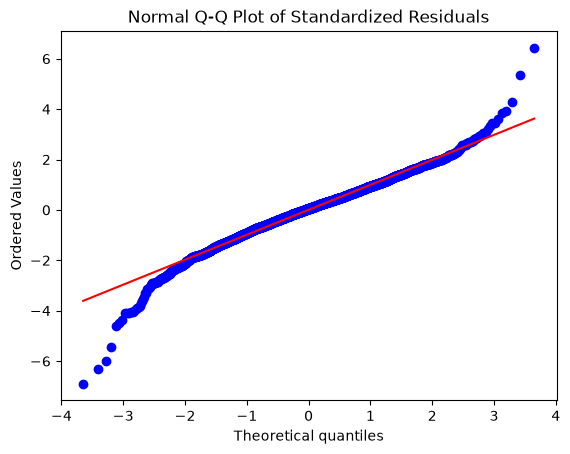

In [70]:
import scipy.stats as stats

stats.probplot(std_resid_norm, dist="norm", plot=plt)
plt.title("Normal Q-Q Plot of Standardized Residuals")
plt.show()

In [69]:
garch_t = arch_model(
    resid * 100,
    mean="Zero",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
).fit(disp="off")

print(garch_t.summary())

                          Zero Mean - GARCH Model Results                           
Dep. Variable:                         None   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -11391.9
Distribution:      Standardized Student's t   AIC:                           22791.7
Method:                  Maximum Likelihood   BIC:                           22818.0
                                              No. Observations:                 5245
Date:                      Sun, Oct 11 2026   Df Residuals:                     5245
Time:                              15:37:27   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omeg

In [37]:
std_resid_t = garch_t.std_resid.dropna()
lb_std_t = acorr_ljungbox(
    std_resid_t,
    lags=[10],
    return_df=True
)

lb_std_t

,lb_stat,lb_pvalue
10,6.564393,0.765829


In [38]:
lb_std_sq_t = acorr_ljungbox(
    std_resid_t**2,
    lags=[10],
    return_df=True
)

lb_std_sq_t

,lb_stat,lb_pvalue
10,18.45309,0.047785


In [39]:
garch21_t = arch_model(
    resid * 100,
    mean="Zero",
    vol="GARCH",
    p=2,
    q=1,
    dist="t"
).fit(disp="off")

print(garch21_t.summary())

                          Zero Mean - GARCH Model Results                           
Dep. Variable:                         None   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -11391.9
Distribution:      Standardized Student's t   AIC:                           22793.7
Method:                  Maximum Likelihood   BIC:                           22826.6
                                              No. Observations:                 5245
Date:                      Sat, Oct 10 2026   Df Residuals:                     5245
Time:                              23:23:17   Df Model:                            0
                               Volatility Model                              
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
o

In [40]:
garch12_t = arch_model(
    resid * 100,
    mean="Zero",
    vol="GARCH",
    p=1,
    q=2,
    dist="t"
).fit(disp="off")

print(garch12_t.summary())

                          Zero Mean - GARCH Model Results                           
Dep. Variable:                         None   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -11391.6
Distribution:      Standardized Student's t   AIC:                           22793.3
Method:                  Maximum Likelihood   BIC:                           22826.1
                                              No. Observations:                 5245
Date:                      Sat, Oct 10 2026   Df Residuals:                     5245
Time:                              23:23:24   Df Model:                            0
                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
omega     

In [41]:
std21 = garch21_t.std_resid.dropna()

acorr_ljungbox(
    std21**2,
    lags=[10],
    return_df=True
)

,lb_stat,lb_pvalue
10,18.452362,0.047796


In [63]:
std12 = garch12_t.std_resid.dropna()

acorr_ljungbox(
    std12**2,
    lags=[10],
    return_df=True
)

,lb_stat,lb_pvalue
10,15.200871,0.124908


In [75]:
rolling_test = test

pred_ret = []
pred_vol = []
actual_ret = []
forecast_dates = []

print("Number of test observations:", len(rolling_test))

Number of test observations: 1312


In [76]:
for i in range(len(rolling_test)):

    if i % 100 == 0:
        print(i, "of", len(rolling_test))

    history = ret.iloc[:split + i].reset_index(drop=True)

    arma_fit = ARIMA(
    history,
    order=(0,0,2),
    trend="n"
).fit()

    mean_forecast = arma_fit.forecast(steps=1).iloc[0]

    resid_history = arma_fit.resid.dropna()

    garch_fit = arch_model(
        resid_history * 100,
        mean="Zero",
        vol="GARCH",
        p=1,
        q=1,
        dist="t"
    ).fit(disp="off")

    garch_forecast = garch_fit.forecast(
        horizon=1,
        reindex=False
    )

    variance_forecast = garch_forecast.variance.iloc[-1, 0]
    volatility_forecast = np.sqrt(variance_forecast) / 100

    pred_ret.append(mean_forecast)
    pred_vol.append(volatility_forecast)
    actual_ret.append(rolling_test.iloc[i])
    forecast_dates.append(rolling_test.index[i])

0 of 1312


C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarni

100 of 1312


C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


200 of 1312


C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarni

... (17 outputs left out)

C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarni

1200 of 1312


C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Kristin\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


1300 of 1312


In [77]:
rolling_results = pd.DataFrame({
    "actual_return": actual_ret,
    "forecast_return": pred_ret,
    "forecast_volatility": pred_vol
}, index=forecast_dates)

print("Number of test forecasts:", len(rolling_results))
rolling_results.head()

Number of test forecasts: 1312


,actual_return,forecast_return,forecast_volatility
2021-07-22,0.022644,-0.001279,0.028202
2021-07-23,0.002222,-0.001470,0.027853
2021-07-26,-0.002222,-0.000615,0.026698
2021-07-27,-0.003622,-0.000042,0.025595
2021-07-28,0.010275,0.000122,0.024572


In [78]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# MA(2)-GARCH(1,1)-t forecast accuracy
mae_model = mean_absolute_error(
    rolling_results["actual_return"],
    rolling_results["forecast_return"]
)

rmse_model = np.sqrt(
    mean_squared_error(
        rolling_results["actual_return"],
        rolling_results["forecast_return"]
    )
)

# Zero-return / no-change benchmark
zero_forecast = np.zeros(len(rolling_results))

mae_zero = mean_absolute_error(
    rolling_results["actual_return"],
    zero_forecast
)

rmse_zero = np.sqrt(
    mean_squared_error(
        rolling_results["actual_return"],
        zero_forecast
    )
)

# Directional accuracy
actual_direction = np.sign(
    rolling_results["actual_return"]
)

forecast_direction = np.sign(
    rolling_results["forecast_return"]
)

direction_accuracy = np.mean(
    actual_direction == forecast_direction
)

print("Model MAE:", mae_model)
print("Zero benchmark MAE:", mae_zero)
print("Model RMSE:", rmse_model)
print("Zero benchmark RMSE:", rmse_zero)
print("Directional accuracy:", direction_accuracy)

Model MAE: 0.01899884819262002
Zero benchmark MAE: 0.019006072621593418
Model RMSE: 0.02599478504497017
Zero benchmark RMSE: 0.025996695328533232
Directional accuracy: 0.5121951219512195


In [79]:
## Latest 1/5/20/60-Day Forecast

In [94]:
yahoo_latest = pd.read_csv(
    "Data/raw/yahoo_daily.csv",
    index_col="date",
    parse_dates=True
)

price_latest = yahoo_latest["wti_fut"].dropna()

print("Latest available date:", price_latest.index[-1])
print("Latest WTI futures price:", price_latest.iloc[-1])

Latest available date: 2026-10-09 00:00:00
Latest WTI futures price: 91.8499984741211


In [95]:
price_positive_latest = price_latest.copy()
price_positive_latest[price_positive_latest <= 0] = np.nan

ret_latest = np.log(price_positive_latest).diff().dropna()

print("Number of return observations:", len(ret_latest))
print("Latest return date:", ret_latest.index[-1])

Number of return observations: 6558
Latest return date: 2026-10-09 00:00:00


In [96]:
ma2_latest = ARIMA(
    ret_latest.reset_index(drop=True),
    order=(0,0,2),
    trend="n"
).fit()

print(ma2_latest.summary())

                               SARIMAX Results                                
Dep. Variable:                wti_fut   No. Observations:                 6558
Model:                 ARIMA(0, 0, 2)   Log Likelihood               14560.054
Date:                Sun, 11 Oct 2026   AIC                         -29114.107
Time:                        19:24:53   BIC                         -29093.742
Sample:                             0   HQIC                        -29107.066
                               - 6558                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.0149      0.005     -2.886      0.004      -0.025      -0.005
ma.L2         -0.0274      0.006     -4.631      0.000      -0.039      -0.016
sigma2         0.0007   4.19e-06    164.912      0.0

In [97]:
resid_latest = ma2_latest.resid.dropna()

garch_latest = arch_model(
    resid_latest * 100,
    mean="Zero",
    vol="GARCH",
    p=1,
    q=1,
    dist="t"
).fit(disp="off")

print(garch_latest.summary())

                          Zero Mean - GARCH Model Results                           
Dep. Variable:                         None   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -14361.6
Distribution:      Standardized Student's t   AIC:                           28731.1
Method:                  Maximum Likelihood   BIC:                           28758.3
                                              No. Observations:                 6558
Date:                      Sun, Oct 11 2026   Df Residuals:                     6558
Time:                              19:24:53   Df Model:                            0
                              Volatility Model                              
                 coef    std err          t      P>|t|      95.0% Conf. Int.
----------------------------------------------------------------------------
omeg

In [98]:
horizon = 60

return_forecast = ma2_latest.forecast(steps=horizon)

In [106]:
garch_forecast = garch_latest.forecast(
    horizon=horizon,
    reindex=False
)

variance_forecast = garch_forecast.variance.iloc[-1].values

volatility_forecast = np.sqrt(variance_forecast) / 100

In [107]:
last_price = price_latest.iloc[-1]

In [108]:
cumulative_return_forecast = np.cumsum(return_forecast)

price_forecast = last_price * np.exp(cumulative_return_forecast)

In [109]:
forecast_horizons = [1, 5, 20, 60]

latest_forecasts = pd.DataFrame({
    "Horizon": forecast_horizons,
    "Forecast Price": [
        price_forecast.iloc[h-1]
        for h in forecast_horizons
    ],
    "Daily Volatility": [
        volatility_forecast[h-1]
        for h in forecast_horizons
    ]
})

latest_forecasts

,Horizon,Forecast Price,Daily Volatility
0,1,91.755170,0.024033
1,5,91.744907,0.024103
2,20,91.744907,0.024337
3,60,91.744907,0.024773


In [110]:
comparison = latest_forecasts.copy()

comparison["Random Walk Price"] = last_price

comparison["Difference vs RW"] = (
    comparison["Forecast Price"]
    - comparison["Random Walk Price"]
)

comparison["Difference (%)"] = (
    comparison["Difference vs RW"]
    / comparison["Random Walk Price"]
    * 100
)

comparison

,Horizon,Forecast Price,Daily Volatility,Random Walk Price,Difference vs RW,Difference (%)
0,1,91.755170,0.024033,91.849998,-0.094829,-0.103243
1,5,91.744907,0.024103,91.849998,-0.105092,-0.114417
2,20,91.744907,0.024337,91.849998,-0.105092,-0.114417
3,60,91.744907,0.024773,91.849998,-0.105092,-0.114417


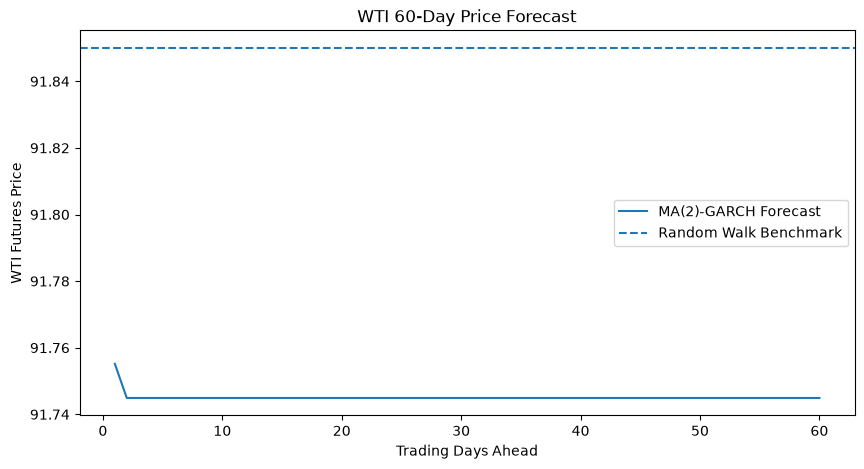

In [111]:
forecast_steps = np.arange(1, horizon + 1)

plt.figure(figsize=(10,5))

plt.plot(
    forecast_steps,
    price_forecast,
    label="MA(2)-GARCH Forecast"
)

plt.axhline(
    y=last_price,
    linestyle="--",
    label="Random Walk Benchmark"
)

plt.xlabel("Trading Days Ahead")
plt.ylabel("WTI Futures Price")
plt.title("WTI 60-Day Price Forecast")

plt.legend()
plt.show()

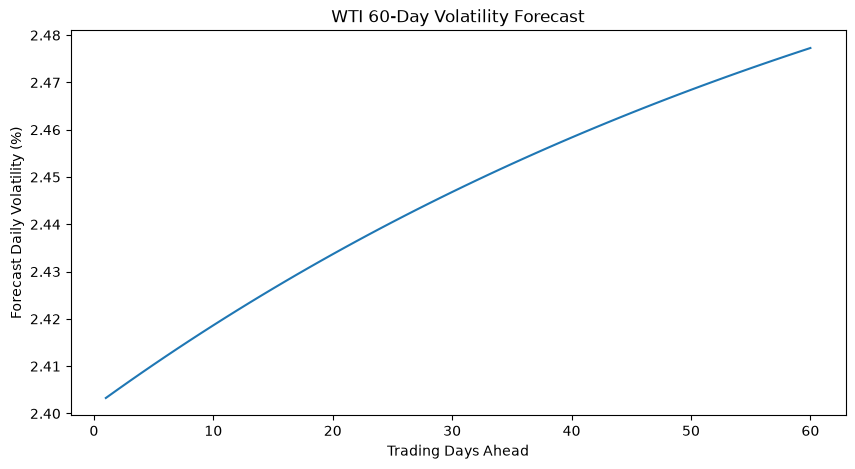

In [112]:
plt.figure(figsize=(10,5))

plt.plot(
    forecast_steps,
    volatility_forecast * 100
)

plt.xlabel("Trading Days Ahead")
plt.ylabel("Forecast Daily Volatility (%)")
plt.title("WTI 60-Day Volatility Forecast")

plt.show()

In [113]:
## Summary and Conclusion